# 03. The flux-ramp bias line as a filter

The flux ramp that linearises the SQUID is generated at room temperature and reaches the SQUID through a long
bias line with parasitic reactances. The line rings after every sharp edge, and that ringing, not the resonator
bandwidth, sets the transient after each ramp reset and each pulse edge in the later notebooks. This notebook
extracts the line's transfer function $H(f)$ from a two-port VNA measurement of the line, as in Sec. IV C of the
paper (Fig. 5 and Table II), checks that the poles are identical to the cached set that notebooks `00`, `06` and
`07` read, and shows in the time domain what the line does to a sawtooth ramp. It then measures the ramp amplitude
from the source voltage recorded at the fridge input on 29 Sep; notebook `06` uses it for its flux-ramp records of
26 Sep, which assumes that the source delivered the same ramp on both days. Data:
`data/flux_line_2026-10-02/flux_line_two_port.s2p`, `data/flux_ramp_source_2026-09-29/source_<rate>kHz.npz` and
the configuration `configs/nist_res2_2026-09-26.toml`. The whole notebook runs in a few seconds.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import umux_cmt as uc
from umux_cmt.plotting import *      # use_style, save, SINGLE, DOUBLE, colours, grid
use_style()
DATA, CONFIGS, RESULTS = Path("../data"), Path("../configs"), Path("results")
store = uc.io.ValueStore(RESULTS / "values.json")

S2P = DATA / "flux_line_2026-10-02" / "flux_line_two_port.s2p"
CACHED_POLES = DATA / "flux_line_2026-10-02" / "flux_line_poles.npz"
SOURCE_DIR = DATA / "flux_ramp_source_2026-09-29"
CONFIG = CONFIGS / "nist_res2_2026-09-26.toml"

R_TOT = 1983.0                   # Ohm, multimeter from leg A to leg B: both 1 kOhm resistors plus the coil loop
R_COIL = 12.0                    # Ohm, multimeter, the coil loop alone (pair and input coil, resistors bypassed)
R_SERIES = R_TOT - R_COIL        # Ohm, the series resistors R the ramp is driven through
F_MIN, F_MAX, RTOL = 80e3, 40e6, 1e-2   # window and tolerance of the rational fit

## 1. The two-port measurement

The bias line is a twisted pair from the room-temperature ramp source to the coil on the cold stage, with a
$1\,\mathrm{k\Omega}$ resistor in series with each leg at the fridge input that turns the source voltage into a
current. To measure the line on its own, the two resistors were bypassed and one VNA port was connected to each
leg of the pair, with the VNA grounds on the fridge (the shields), fridge cold, 9 kHz to 100 MHz on a logarithmic
grid. The ports see the pair as a balanced two-port: at low frequency the coil loop simply connects port 1 to
port 2, and the structure above a few MHz is the line's own resonances.

1601 points from 9 kHz to 100 MHz


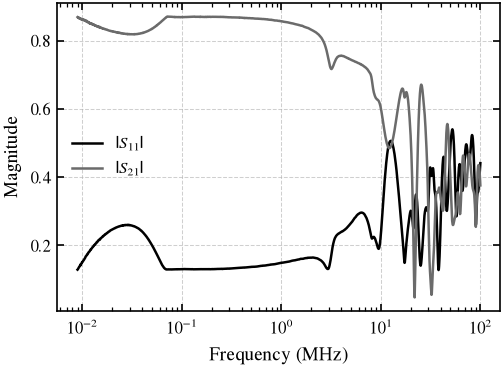

In [2]:
f, S = uc.read_s2p(S2P)
print(f"{len(f)} points from {f[0] / 1e3:.0f} kHz to {f[-1] / 1e6:.0f} MHz")

fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
ax.semilogx(f / 1e6, np.abs(S[:, 0, 0]), color=MEASURED, label="$|S_{11}|$")
ax.semilogx(f / 1e6, np.abs(S[:, 1, 0]), color=GRAY, label="$|S_{21}|$")
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Magnitude")
ax.legend(loc="center left")
grid(ax)
save(fig, "03_two_port", RESULTS / "figures")
plt.show()

## 2. Differential impedance of the pair

The ramp drives the pair differentially, so what matters is the differential-mode reflection
$S_{dd} = (S_{11} - S_{12} - S_{21} + S_{22})/2$ and the differential impedance
$Z_{dd} = 2 Z_0\,(1 + S_{dd})/(1 - S_{dd})$ seen between the two legs (Eq. 28 of the paper). Two checks on the
measurement come for free: the two-port must be reciprocal ($S_{21} = S_{12}$), and a balanced pair should not
convert differential drive into common mode ($|S_{dc}| \ll |S_{dd}|$). The figure shows the low-frequency end of
$Z_{dd}$ (the full $|Z_{dd}|$ follows with the fit in step 3): $\mathrm{Re}\,Z_{dd}$ is the resistance of the coil
loop, $15\,\Omega$ against $12\,\Omega$ on the multimeter at DC, a difference that is negligible next to the
$1971\,\Omega$ of the series resistors, and $\mathrm{Im}\,Z_{dd}$ rises as $2\pi f L$ with the line's series
inductance $L$. Below about 70 kHz both parts show a bump that we do not attribute to the line:
$\mathrm{Im}\,Z_{dd}$ is $10\,\Omega$ at 50 kHz, where $2\pi f L$ is only $1.5\,\Omega$, and the bump ends in a kink
at about 71 kHz that is also visible in $|S_{11}|$ and $|S_{21}|$, most likely an artefact at the bottom of the VNA's
range. The fit window of step 3 starts at 80 kHz to leave it out.

reciprocity below 8 MHz:  max |S21 - S12| = 0.0082
balance below 8 MHz:      max |Sdc / Sdd| = 0.0062
loop resistance:          Re Zdd = 15.1 Ohm at 9 kHz, 14.9-15.1 Ohm at 80-200 kHz  (multimeter 12 Ohm)
series inductance:        Im Zdd / 2 pi f = 4.9 uH at 0.2-1 MHz


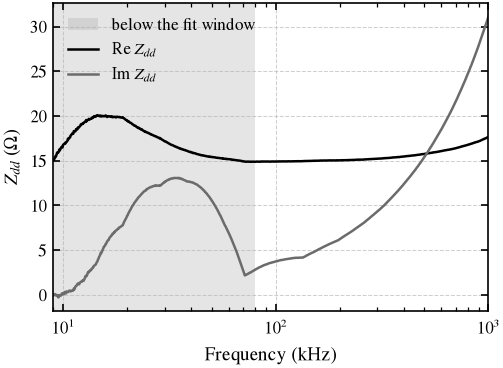

In [3]:
Sdd, Sdc, Zdd = uc.differential_impedance(f, S[:, 0, 0], S[:, 1, 0], S[:, 0, 1], S[:, 1, 1])

low = f < 8e6
plateau = (f >= F_MIN) & (f <= 200e3)
inductive = (f >= 200e3) & (f <= 1e6)
L_series = np.median(Zdd.imag[inductive] / (2 * np.pi * f[inductive]))
print(f"reciprocity below 8 MHz:  max |S21 - S12| = {np.max(np.abs(S[low, 1, 0] - S[low, 0, 1])):.4f}")
print(f"balance below 8 MHz:      max |Sdc / Sdd| = {np.max(np.abs(Sdc[low] / Sdd[low])):.4f}")
print(f"loop resistance:          Re Zdd = {Zdd[0].real:.1f} Ohm at {f[0] / 1e3:.0f} kHz, "
      f"{Zdd[plateau].real.min():.1f}-{Zdd[plateau].real.max():.1f} Ohm at 80-200 kHz  (multimeter {R_COIL:.0f} Ohm)")
print(f"series inductance:        Im Zdd / 2 pi f = {L_series * 1e6:.1f} uH at 0.2-1 MHz")

lowf = f <= 1e6
fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
ax.axvspan(f[0] / 1e3, F_MIN / 1e3, color=ZERO, alpha=0.25, lw=0, label="below the fit window")
ax.semilogx(f[lowf] / 1e3, Zdd[lowf].real, color=MEASURED, label=r"Re $Z_{dd}$")
ax.semilogx(f[lowf] / 1e3, Zdd[lowf].imag, color=GRAY, label=r"Im $Z_{dd}$")
ax.set_xlim(f[0] / 1e3, 1e3)
ax.set_xlabel("Frequency (kHz)")
ax.set_ylabel(r"$Z_{dd}$ ($\Omega$)")
ax.legend(loc="upper left")
grid(ax)
save(fig, "03_differential_impedance", RESULTS / "figures")
plt.show()

## 3. The poles of the coil current

The ramp source drives the pair through the series resistors $R$, so it sees the impedance $R + Z_{dd}(s)$, and
the natural frequencies of the driven circuit are the zeros of that impedance, $R + Z_{dd}(p_k) = 0$: after an
edge, every current on the line, the coil current included, rings and decays at these complex frequencies $p_k$.
The measurement sees the line only from its input. It gives the current entering the pair, $V/(R + Z_{dd})$, but
not the coil current at the far end, which differs from it wherever the capacitance of the pair carries part of
the current, most of all near the line's resonances; the zeros of the coil current are not determined. As in the
paper we therefore *assume* an all-pole transfer function from source current to coil current,
$H(s) = \prod_k (1 - s/p_k)^{-1}$, normalised to $H(0) = 1$ so that the DC flux calibration passes through
unchanged (Eq. 30). Notebooks `06` and `07` test this assumption on measured IQ records without adjusting $H$.

The poles are found by fitting a rational function to $R + Z_{dd}$ on the imaginary axis with the AAA algorithm
(both signs of frequency, so the fit is real) between 80 kHz and 40 MHz, and keeping the roots with negative real
part that come in conjugate pairs. Nothing here is fitted to SQUID data: the inputs are the two-port,
$R = R_\mathrm{tot} - R_\mathrm{coil} = 1983 - 12\,\Omega$ (multimeter readings from leg A to leg B with the
resistors and with the resistors bypassed) and the fit window and tolerance. The poles are compared with the
cached set shipped in `data/` and saved again into `results/`.

In [4]:
out = uc.poles_from_s2p(S2P, R_SERIES, f_min=F_MIN, f_max=F_MAX, rtol=RTOL)
tf = uc.FluxLineTF(out["poles_hz"])
modes = tf.mode_table()                          # (f, Q, tau) of each mode, by frequency

print(f"AAA fit: {out['n_terms']} terms, max relative error {out['max_rel_err']:.1e} on R + Zdd")
print(f"{'':4} {'f (MHz)':>8} {'Q':>6} {'tau (ns)':>9}")
for k, (fk, Qk, tauk) in enumerate(modes, 1):
    print(f"p{k:<3} {fk / 1e6:8.2f} {Qk:6.1f} {tauk * 1e9:9.0f}")

cached = uc.FluxLineTF.from_file(CACHED_POLES)
diff = np.abs(np.sort_complex(tf.poles) - np.sort_complex(cached.poles))
print(f"\nlargest difference from the cached poles: {diff.max():.1e} Hz")

tf.save(RESULTS / "flux_line_poles.npz", R_series=R_SERIES, f_min=F_MIN, f_max=F_MAX, rtol=RTOL, s2p=str(S2P))

AAA fit: 12 terms, max relative error 4.5e-03 on R + Zdd
      f (MHz)      Q  tau (ns)
p1       4.53    5.6       395
p2      14.02    6.2       142
p3      22.88   11.3       157
p4      33.89    7.4        70

largest difference from the cached poles: 0.0e+00 Hz


The fit is judged on $R + Z_{dd}$, in which $R$ is the larger part at every frequency: $|Z_{dd}|$ peaks at only
$0.8\,\mathrm{k\Omega}$, at $p_1$. The low peak reflects the line's own loss. Near $p_1$ the line is a parallel
resonance with a $Q$ of about 8 of its own, and $R$, which loads it from the source side, lowers that to 5.6, so
most of the damping of the ringing comes from the line itself (a larger $R$ would damp it less, see "What to try
next"). The overlay is the fit minus $R$: it is accurate where $|Z_{dd}|$ is large enough to matter for the poles.

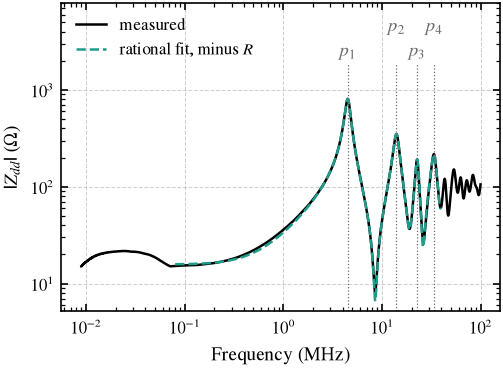

In [5]:
window = (f >= F_MIN) & (f <= F_MAX)
Zdd_fit = out["fit"](1j * f[window] / 1e6) - R_SERIES

fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
ax.loglog(f / 1e6, np.abs(Zdd), color=MEASURED, label="measured")
ax.loglog(f[window] / 1e6, np.abs(Zdd_fit), color=TEAL, ls="--", label="rational fit, minus $R$")
for k, fk in enumerate(modes[:, 0], 1):
    ax.axvline(fk / 1e6, ymax=0.8, color=GRAY, lw=0.6, ls=":")
    ax.text(fk / 1e6, 0.81 if k % 2 else 0.89, f"$p_{k}$", color=GRAY, ha="center", va="bottom",
            transform=ax.get_xaxis_transform())
ax.set_ylim(top=8e3)
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel(r"$|Z_{dd}|$ ($\Omega$)")
ax.legend(loc="upper left")
grid(ax)
save(fig, "03_impedance_fit", RESULTS / "figures")
plt.show()

## 4. The transfer function against the resonator bandwidth (Fig. 5, Table II)

$|H(f)|$ is flat to within 6% up to 1 MHz, peaks by a factor of almost 7 at $p_1$ and falls off steeply above
the poles. The resonator's bandwidth $f_r/Q_r$, from the configuration that notebook `01` extracted, marks the
frequencies the resonator can follow; there $|H| = 1.02$. For ramp rates up to about $f_r/Q_r$ the ramp's
fundamental therefore passes through the line almost unchanged, and only the high harmonics that make up the sharp
reset are amplified near $p_1$, which is the ringing; at the fastest rates of notebook `06` the fundamental is
affected too (the line `|H| at ramp rates` printed below). Table II compares the $1/e$ decay time $\tau = Q/\pi f$ of every mode
with the resonator's ring-up time $\tau_r = 2Q_r/\omega_r$: the dominant line mode decays in about 400 ns,
comparable to the 550 ns of the resonator, so after a reset the two transients overlap.

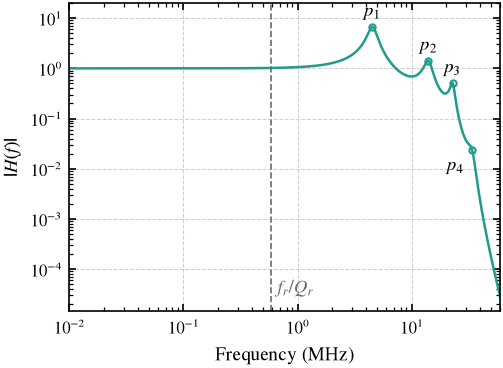

                      f (MHz)       Q  tau (ns)  |H(f)|
resonator, fr/Qr        0.580    9515       549    1.02
p1                       4.53     5.6       395     6.7
p2                      14.02     6.2       142     1.4
p3                      22.88    11.3       157    0.50
p4                      33.89     7.4        70   0.024

|H| at ramp rates:  0.1 MHz 1.00, 0.5 MHz 1.01, 1 MHz 1.06, 1.5 MHz 1.14, 2 MHz 1.27

recorded: PoleOneF 4.53 MHz, PoleOneQ 5.6, PoleOneTau 395 ns, ResBW 580 kHz, HatResBW 1.02


In [6]:
cfg = uc.Config(CONFIG)
fr, Qr = cfg.f0s[0], cfg.Qrs[0]
bw = fr / Qr
tau_r = 2 * Qr / (2 * np.pi * fr)

ff = np.logspace(4, np.log10(60e6), 1000)
fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
ax.loglog(ff / 1e6, np.abs(tf.H(ff)), color=TEAL)
ax.plot(modes[:, 0] / 1e6, np.abs(tf.H(modes[:, 0])), "o", mfc="none", color=TEAL)
for k, fk in enumerate(modes[:, 0], 1):
    ax.annotate(f"$p_{k}$", (fk / 1e6, np.abs(tf.H(fk))), xytext=(0, 5) if k < 4 else (-4, -10),
                textcoords="offset points", ha="center" if k < 4 else "right")
ax.axvline(bw / 1e6, color=GRAY, ls="--", lw=0.8)
ax.text(bw / 1e6 * 1.15, 0.06, "$f_r/Q_r$", color=GRAY, transform=ax.get_xaxis_transform())
ax.set_xlim(ff[0] / 1e6, ff[-1] / 1e6)
ax.set_ylim(top=20)
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("$|H(f)|$")
grid(ax)
save(fig, "03_flux_line_tf", RESULTS / "figures")
plt.show()

print(f"{'':20} {'f (MHz)':>8} {'Q':>7} {'tau (ns)':>9} {'|H(f)|':>7}")
print(f"{'resonator, fr/Qr':20} {bw / 1e6:8.3f} {Qr:7.0f} {tau_r * 1e9:9.0f} {np.abs(tf.H(bw)):7.2f}")
for k, (fk, Qk, tauk) in enumerate(modes, 1):
    print(f"{'p' + str(k):20} {fk / 1e6:8.2f} {Qk:7.1f} {tauk * 1e9:9.0f} {np.abs(tf.H(fk)):#7.2g}")
print("\n|H| at ramp rates:  " + ", ".join(f"{r / 1e6:g} MHz {np.abs(tf.H(r)):.2f}" for r in (0.1e6, 0.5e6, 1e6, 1.5e6, 2e6)))

store.record("PoleOneF", modes[0, 0] / 1e6, "{:.2f}", "dominant pole of the flux line, MHz (03)")
store.record("PoleOneQ", modes[0, 1], "{:.1f}", "Q of the dominant pole (03)")
store.record("PoleOneTau", modes[0, 2] * 1e9, "{:.0f}", "1/e decay time of the dominant pole, ns (03)")
store.record("ResBW", bw / 1e3, "{:.0f}", "resonator bandwidth f0/Qr of the 09/26 configuration, kHz (03)")
store.record("HatResBW", np.abs(tf.H(bw)), "{:.2f}", "|H| of the flux line at the resonator bandwidth (03)")
print(f"\nrecorded: PoleOneF {store.text('PoleOneF')} MHz, PoleOneQ {store.text('PoleOneQ')}, "
      f"PoleOneTau {store.text('PoleOneTau')} ns, ResBW {store.text('ResBW')} kHz, HatResBW {store.text('HatResBW')}")

## 5. What the line does in the time domain

The step response follows from the poles in closed form: the coil current overshoots to 1.8 times the step and
rings at $p_1$ for about a microsecond (it stays within 10% of the step after 0.9 $\mu$s and within 1% after
1.9 $\mu$s). A sawtooth ramp is a step of minus one amplitude at every reset, so the coil flux drops below the
reset value and rings before it rejoins the ramp. `apply_periodic` multiplies every harmonic of the periodic drive
by $H(f)$, which gives the steady state of a line driven for ever. At 1 MHz the ringing has not died out by the
next reset; at 100 kHz it is over within the first fifth of the period. Notebook `06` follows this same ringing in
the measured IQ records at every rate from 1 kHz to 2 MHz.

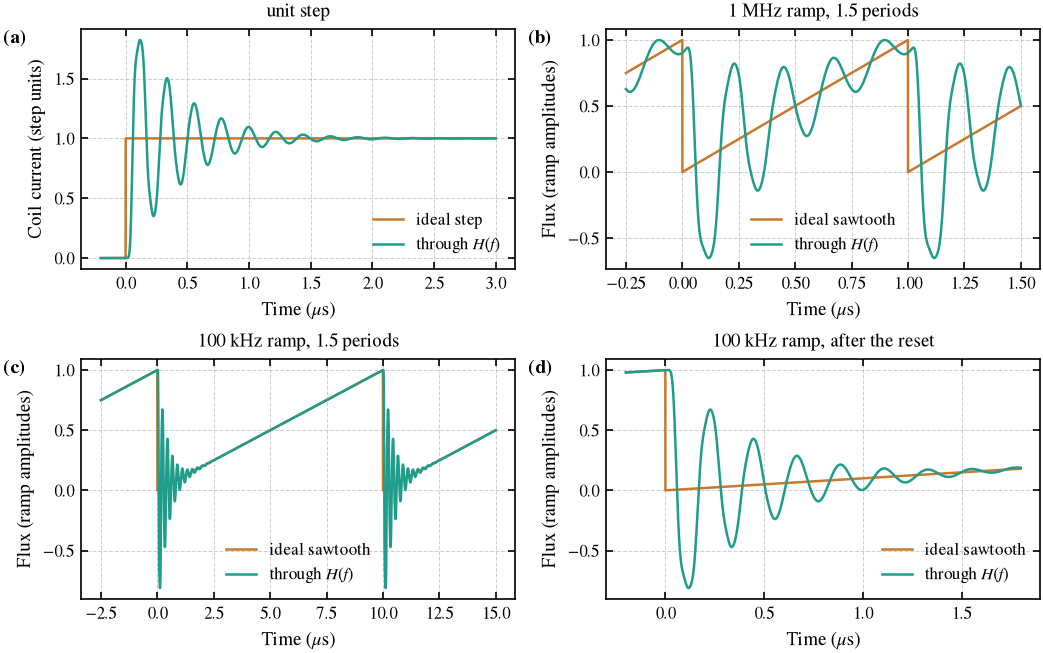

step response: peak 1.82 at 118 ns, within 10% of the step after 0.91 us, within 1% after 1.89 us
lowest coil flux after the reset: -0.65 at 1000 kHz, -0.81 at 100 kHz (ramp amplitudes; the ideal sawtooth starts at 0)


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(DOUBLE, 4.4))

t_step = np.linspace(-0.2e-6, 3e-6, 3201)
step = tf.step(t_step)
settled = {tol: t_step[np.abs(step - 1) > tol][-1] for tol in (0.1, 0.01)}
axes[0, 0].plot(t_step * 1e6, np.where(t_step >= 0, 1.0, 0.0), color=ORANGE, label="ideal step")
axes[0, 0].plot(t_step * 1e6, step, color=TEAL, label="through $H(f)$")
axes[0, 0].set_ylabel("Coil current (step units)")
axes[0, 0].set_title("unit step")

panels = [(1e6, -0.25, 1.5, "1 MHz ramp, 1.5 periods"),
          (1e5, -0.25, 1.5, "100 kHz ramp, 1.5 periods"),
          (1e5, -0.02, 0.18, "100 kHz ramp, after the reset")]
lowest = {}
for ax, (rate, u0, u1, title) in zip(axes.flat[1:], panels):
    ideal = uc.signals.sawtooth(rate, amplitude=1.0)
    coil = tf.apply_periodic(ideal, 1 / rate)
    lowest[rate] = coil(np.linspace(0, 1, 4001) / rate).min()
    t = np.linspace(u0, u1, 4000) / rate
    ax.plot(t * 1e6, ideal(t), color=ORANGE, label="ideal sawtooth")
    ax.plot(t * 1e6, coil(t), color=TEAL, label="through $H(f)$")
    ax.set_ylabel("Flux (ramp amplitudes)")
    ax.set_title(title)

for ax, loc in zip(axes.flat, ("lower right", "lower center", "lower center", "lower right")):
    ax.set_xlabel(r"Time ($\mu$s)")
    ax.legend(loc=loc)
    grid(ax)
panel_labels(axes.flat)
save(fig, "03_time_domain", RESULTS / "figures")
plt.show()

print(f"step response: peak {step.max():.2f} at {t_step[step.argmax()] * 1e9:.0f} ns, "
      f"within 10% of the step after {settled[0.1] * 1e6:.2f} us, within 1% after {settled[0.01] * 1e6:.2f} us")
print("lowest coil flux after the reset: " + ", ".join(f"{v:.2f} at {r / 1e3:g} kHz" for r, v in lowest.items())
      + " (ramp amplitudes; the ideal sawtooth starts at 0)")

## 6. The amplitude of the flux ramp

The flux-ramp records of notebook `06` were taken on 26 Sep with a nominal $1\,\Phi_0$ sawtooth; predicting them
needs the true amplitude. On 29 Sep the source voltage was recorded directly at the fridge-input BNC (digitizer at
$1\,\mathrm{M\Omega}$, fridge connected, so under load and with no correction needed for the source's output
resistance) at thirteen ramp rates from 1 kHz to 2 MHz. Using it for the 26 Sep records assumes that the source
delivered the same ramp on both days (same settings, no drift). For each record the periods are cut at the resets, a
straight line is fitted to the samples between 15% and 95% of each period (away from the reset transient), and the
slopes, in volts per period, are averaged over the periods and over all rates. The DC coil current is this voltage
over $R_\mathrm{tot} = 1983\,\Omega$ (multimeter, both series resistors and the coil loop), and the mutual
$M_{fr}$ fitted in notebook `01` (the 09/26 configuration) turns it into flux:
$\Phi / V = M_{fr} / (\Phi_0 R_\mathrm{tot})$. The amplitude is stored for the later notebooks.

In [8]:
def ramp_periods(record):
    y, n = record.z.real, int(round(record.fs / record.rate))
    resets = np.where(np.diff(y) < -0.5 * np.ptp(y))[0] + 1
    return np.array([y[r:r + n] for r in resets if r + n <= len(y)])


def volts_per_period(periods):
    u = np.arange(periods.shape[1]) / periods.shape[1]
    keep = (u > 0.15) & (u < 0.95)
    return np.mean([np.polyfit(u[keep], p[keep], 1)[0] for p in periods])


records = sorted((uc.load_record(p) for p in SOURCE_DIR.glob("source_*kHz.npz")), key=lambda r: r.rate)
records = [r for r in records if r.rate <= 2e6]
phi_per_volt = cfg.Mfrs[0] / cfg.Phi0 / R_TOT

amps = {}
print(f"{'rate (kHz)':>10} {'fs (MS/s)':>10} {'samples/period':>15} {'periods cut':>12} {'amplitude (mV)':>15}")
for rec in records:
    periods = ramp_periods(rec)
    amps[rec.rate] = volts_per_period(periods)
    print(f"{rec.rate / 1e3:10g} {rec.fs / 1e6:10g} {rec.fs / rec.rate:15.1f} {len(periods):>6d} of {rec.n_periods:2.0f} "
          f"{amps[rec.rate] * 1e3:15.1f}")

ramp_V = np.mean(list(amps.values()))
ramp_phi = ramp_V * phi_per_volt
spread = np.ptp(list(amps.values())) / ramp_V
store.record("RampAmp", ramp_V * 1e3, "{:.1f}", "flux-ramp amplitude at the fridge input, mV per period (03)")
store.record("RampAmpPhi", ramp_phi, "{:.3f}", "flux-ramp amplitude in Phi0 with the 09/26 Mfr and R_tot (03)")
store.record("Rflux", R_SERIES / 1e3, "{:.3f}", "series resistors R driving the flux line (R_tot - R_coil), kOhm (03)")

print(f"\nramp amplitude {ramp_V * 1e3:.1f} mV per period (spread over rates {spread * 100:.1f}%)")
print(f"               = {ramp_V / R_TOT * 1e6:.1f} uA = {ramp_phi:.3f} Phi0  "
      f"(Mfr = {cfg.Mfrs[0] * 1e12:.2f} pH, R_tot = {R_TOT:.0f} Ohm)")
print(f"recorded: RampAmp {store.text('RampAmp')} mV, RampAmpPhi {store.text('RampAmpPhi')}, Rflux {store.text('Rflux')} kOhm")

rate (kHz)  fs (MS/s)  samples/period  periods cut  amplitude (mV)
         1        0.2           200.0      9 of 10           271.2
        10          2           200.0      9 of 10           270.6
        20          4           200.0      9 of 10           270.7
        50         10           200.0      9 of 10           271.2
        75         15           200.0      9 of 10           271.1
       100         20           200.0      9 of 10           271.3
       200         40           200.0      9 of 10           270.5
       300         40           133.3     14 of 15           267.9
       500         40            80.0     24 of 25           267.5
       750         30            40.0      9 of 10           266.6
      1000         40            40.0      9 of 10           266.4
      1500         40            26.7     14 of 15           269.0
      2000         40            20.0     11 of 20           265.5

ramp amplitude 269.2 mV per period (spread over rates 2.1%)
 

Up to 200 kHz the amplitudes agree within 0.3% (mean 270.9 mV); at higher rates they are 1-2% lower and fall with
the rate, for reasons we do not know, and this drop makes up most of the 2.1% spread. Two details come from the simple period cut,
which we keep because it is the paper's method. Where a period is not a whole number of samples (300 kHz and
1.5 MHz) the phase axis $u = k/n$ with the rounded $n$ is stretched, which biases those two slopes by $-0.25\%$ and
$+1.25\%$ (and the mean by $+0.07\%$); this is why 1.5 MHz stands out. At 2 MHz the reset is spread over two samples
and in many periods neither drop reaches half the peak-to-peak, so only 11 of the 20 periods are cut.

The 200 kHz record resolves the reset well (200 samples per period at 40 MS/s). Its averaged period, converted to
flux, is compared with the ideal sawtooth of the fitted amplitude, aligned to the record's DC level, and with that
sawtooth through $H(f)$. The measured source follows the ideal sawtooth through the reset; the ringing is what the
line adds between the source and the SQUID, and it is the teal curve, not the measured source, that the
simulations of notebook `06` drive the SQUID with.

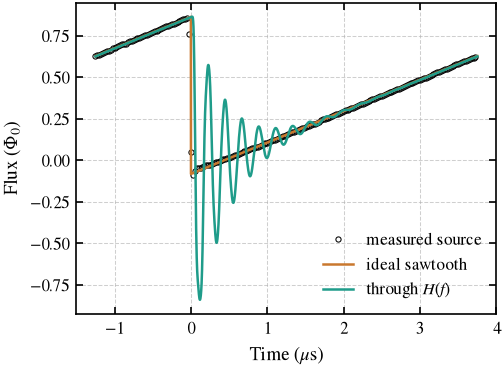

In [9]:
rec = next(r for r in records if r.rate == 200e3)
rate, periods = rec.rate, ramp_periods(rec)
n = periods.shape[1]
u = np.arange(n) / n
measured = periods.mean(axis=0) * phi_per_volt
mid = (u > 0.15) & (u < 0.95)
start = np.mean(measured[mid] - ramp_phi * u[mid])

ideal = uc.signals.sawtooth(rate, amplitude=ramp_phi, offset=start)
coil = tf.apply_periodic(ideal, 1 / rate)
t_meas = np.where(u >= 0.75, u - 1, u) / rate
t = np.linspace(-0.25, 0.75, 4000) / rate

fig, ax = plt.subplots(figsize=(SINGLE, 2.5))
ax.plot(t_meas * 1e6, measured, "o", mfc="none", color=MEASURED, mew=0.5, ms=2.5, label="measured source")
ax.plot(t * 1e6, ideal(t), color=ORANGE, label="ideal sawtooth")
ax.plot(t * 1e6, coil(t), color=TEAL, label="through $H(f)$")
ax.set_xlabel(r"Time ($\mu$s)")
ax.set_ylabel(r"Flux ($\Phi_0$)")
ax.legend(loc="lower right")
grid(ax)
save(fig, "03_ramp_amplitude", RESULTS / "figures")
plt.show()

## What to try next

* **The line damps itself.** Recompute the poles with `uc.poles_from_impedance(f, Zdd, R)` for $R$ from
  $200\,\Omega$ to $10\,\mathrm{k\Omega}$ in place of `R_SERIES` and watch $Q_1$ and the step overshoot: $Q_1$ rises
  only from 1.7 to 7.3 and levels off near the line's own $Q \approx 8$, because $R$ loads the parallel resonance
  at $p_1$, $Q_1 \approx Q_\mathrm{line}\,R/(R + |Z_{dd}|_\mathrm{max})$; a larger resistor damps less. At
  10 to $50\,\Omega$ the modes move to the line's series resonances instead, the first near 8.5 MHz, where
  $|Z_{dd}|$ has its minimum.
* **How robust the poles are.** $p_4$ lies near the upper edge of the 80 kHz to 40 MHz fit window. Move `F_MAX` to
  30 or 60 MHz, or set `RTOL = 3e-3`: $p_1$ to $p_3$, $|H(f_r/Q_r)|$ and the 100 kHz coil flux barely move, and
  $p_4$ is the least robust. Do not tighten `RTOL` further: at `1e-3` (with `F_MAX` at 30 or 60 MHz) AAA adds
  spurious pole-zero pairs next to $p_1$ (Froissart doublets), which cancel in the fit but enter $H$ as full poles,
  because $H$ keeps only the zeros of $R + Z_{dd}$. `mode_table()` then lists an extra mode near 4.5 MHz with $Q$
  of 100 or more, and after a 100 kHz reset the coil flux drops to $-5$ or $-275$ ramp amplitudes instead of
  $-0.8$. A mode with $Q$ well above 10 is the sign of an over-tight fit; `poles_from_impedance` does not filter
  such modes out.
* **Your own bias line.** A two-port `.s2p` of any line (ports on the two legs, shields on the cryostat, series
  resistors bypassed) gives its poles with `uc.FluxLineTF.from_s2p(path, R_series)`; check `mode_table()`, save
  them with `tf.save` and point notebooks `06` and `07` at that file in place of `flux_line_poles.npz`.